# Bridge Element-Level HI Forecasting with Temporal GNN
This notebook builds a static bridge–element graph from the CSV, creates yearly feature snapshots (2020–2024), trains a Temporal GCN+GRU model to predict next-year element HI, and produces 5-year forecasts (2025–2029) with:
- **Autoregressive HI** feedback (`HI_prev`)
- **Scenario-based** evolution of bridge age, traffic, and weather covariates.

Outputs:
- `element_hi_forecast_2025_2029_AR_scenario.csv`


## 0) Setup
Make sure you have `torch`, `torch_geometric`, and their dependencies installed in the same kernel.
If imports fail, install PyTorch first, then install PyG matching your torch version.

In [1]:
import pandas as pd
import numpy as np

# ---- paths ----
CSV_PATH = "../data/NEW_NBE_and_NBI_FL.csv"  # update if needed

# ---- column names ----
TARGET_COL = "HI"
YEAR_COL = "YEAR"
BRIDGE_ID_COL = "STRUCTURE_NUMBER"
ELEM_NUM_COL = "ELEMENT_NUMBER"
PARENT_ELEM_NUM_COL = "PARENT_ELEMENT_NUMBER"

YEARS = [2020, 2021, 2022, 2023, 2024]


## 1) Graph + snapshot builders
These functions:
- create global node indices for bridge and element nodes
- build static edges (bridge↔element, parent↔child)
- one-hot encode categorical columns
- **coerce to numeric and impute missing/infinite values** (critical to avoid NaNs in GNN)
- build yearly feature matrices `X_t` and labels `y_t`.


In [2]:
from sklearn.feature_extraction import FeatureHasher
import hashlib

def normalize_bridge_id(x) -> str:
    """Ensure STRUCTURE_NUMBER becomes a stable string (avoid float formatting)."""
    if pd.isna(x):
        return None
    try:
        return str(int(float(x)))
    except Exception:
        return str(x)

def build_global_node_index(df: pd.DataFrame):
    bridge_ids = df[BRIDGE_ID_COL].map(normalize_bridge_id)
    elem_nums = df[ELEM_NUM_COL].astype("Int64")

    bridge_nodes = set(f"bridge:{bid}" for bid in bridge_ids.dropna().unique())
    elem_nodes = set(
        f"elem:{bid}:{int(en)}"
        for bid, en in zip(bridge_ids, elem_nums)
        if (bid is not None) and (not pd.isna(en))
    )

    all_nodes = sorted(list(bridge_nodes | elem_nodes))
    node2idx = {k: i for i, k in enumerate(all_nodes)}
    return node2idx, all_nodes, elem_nodes, bridge_nodes

def build_static_edges(df: pd.DataFrame, node2idx: dict):
    edges = []
    b_ids = df[BRIDGE_ID_COL].map(normalize_bridge_id).values
    e_nums = df[ELEM_NUM_COL].astype("Int64").values
    p_nums = df[PARENT_ELEM_NUM_COL].astype("Int64").values if PARENT_ELEM_NUM_COL in df.columns else [pd.NA]*len(df)

    for bid, en, pn in zip(b_ids, e_nums, p_nums):
        if bid is None or pd.isna(en):
            continue

        b_key = f"bridge:{bid}"
        e_key = f"elem:{bid}:{int(en)}"

        if b_key in node2idx and e_key in node2idx:
            b_i = node2idx[b_key]
            e_i = node2idx[e_key]
            edges.append((b_i, e_i))
            edges.append((e_i, b_i))

        if (pn is not None) and (not pd.isna(pn)):
            p_key = f"elem:{bid}:{int(pn)}"
            if p_key in node2idx and e_key in node2idx:
                p_i = node2idx[p_key]
                e_i = node2idx[e_key]
                edges.append((p_i, e_i))
                edges.append((e_i, p_i))

    edges = list(set(edges))
    edge_index = np.array(edges, dtype=np.int64).T
    return edge_index

def hash_categorical_features(df: pd.DataFrame, n_features: int = 128):
    """
    Replace one-hot encoding with feature hashing to reduce memory.
    Maps each categorical feature to a fixed number of hash buckets.
    
    Parameters:
    -----------
    n_features : Fixed number of hash dimensions per feature (default 128)
                 Adjust based on dataset size and memory constraints.
    """
    work = df.copy()

    # bool -> int
    bool_cols = [c for c in work.columns if work[c].dtype == bool]
    for c in bool_cols:
        work[c] = work[c].astype(np.int8)

    # Don't hash IDs
    id_like = {
        YEAR_COL, BRIDGE_ID_COL,
        "LATEST_STRUCTURE_NUMBER", "NBI_8 - Structure Number", "NBI_2025 NBI Structure Number"
    }
    obj_cols = [c for c in work.columns if work[c].dtype == "object" and c not in id_like]

    # Drop ID columns early
    drop_cols = [c for c in list(id_like) if c in work.columns]
    work = work.drop(columns=drop_cols, errors="ignore")

    # Hash each categorical column independently
    hash_features = []
    for col in obj_cols:
        col_name = col
        # Convert to string, handle NaN
        col_values = work[col].fillna("__NA__").astype(str).values
        
        # Create hash-based features: hash each value to range [0, n_features)
        hashed = np.zeros((len(col_values), n_features), dtype=np.float32)
        for i, val in enumerate(col_values):
            # Use hash to determine which buckets activate for this value
            h = int(hashlib.md5(f"{col_name}_{val}".encode()).hexdigest(), 16)
            for j in range(n_features):
                # Multiple hash outputs populate different buckets
                bucket = (h + j) % n_features
                hashed[i, bucket] += 1.0 / (n_features // 4)  # Normalize contribution
        
        hash_features.append(hashed)
    
    # Concatenate all hash features
    if hash_features:
        X_hashed = np.concatenate(hash_features, axis=1)
    else:
        X_hashed = np.zeros((len(work), 0), dtype=np.float32)
    
    # Get numeric columns (excluding the ones we already dropped)
    numeric_cols = [c for c in work.select_dtypes(include=[np.number]).columns]
    X_numeric = work[numeric_cols].values.astype(np.float32)
    
    # Combine numeric + hashed features
    work_final = np.concatenate([X_numeric, X_hashed], axis=1)
    work_final = np.nan_to_num(work_final, nan=0.0)
    work_final = np.where(np.isinf(work_final), 0.0, work_final)
    
    feature_names = numeric_cols + [f"hash_{i}" for i in range(X_hashed.shape[1])]
    
    return pd.DataFrame(work_final, columns=feature_names)

def make_feature_frame(df: pd.DataFrame):
    """
    Process features using hashing instead of one-hot encoding.
    Much more memory-efficient for large datasets.
    """
    # Use hashing with 128 buckets per categorical feature
    # Adjust n_features DOWN if still OOM (try 64, 32)
    # or UP if you have room and want more capacity
    return hash_categorical_features(df, n_features=128)

def build_yearly_matrices(df_raw: pd.DataFrame, node2idx: dict):
    df = df_raw.copy()
    df[BRIDGE_ID_COL] = df[BRIDGE_ID_COL].map(normalize_bridge_id)

    feat_df = make_feature_frame(df)

    drop_cols = [
        TARGET_COL, YEAR_COL, BRIDGE_ID_COL,
        "LATEST_STRUCTURE_NUMBER", "NBI_8 - Structure Number", "NBI_2025 NBI Structure Number"
    ]
    drop_cols = [c for c in drop_cols if c in feat_df.columns]
    feat_df_no_leak = feat_df.drop(columns=drop_cols, errors="ignore")

    feature_cols = list(feat_df_no_leak.columns)
    N = len(node2idx)
    F = len(feature_cols)

    # Node type indicator
    node_type = np.zeros((N, 2), dtype=np.float32)  # [is_bridge, is_element]
    for k, i in node2idx.items():
        if k.startswith("bridge:"):
            node_type[i, 0] = 1.0
        else:
            node_type[i, 1] = 1.0

    X_list, y_list, mask_list = [], [], []

    for year in YEARS:
        sub_raw = df[df[YEAR_COL] == year]
        sub_feat = feat_df_no_leak.loc[sub_raw.index]

        X = np.zeros((N, F + 2), dtype=np.float32)
        y = np.full((N,), np.nan, dtype=np.float32)

        # Element node features + labels
        for ridx, row in sub_raw.iterrows():
            bid = row[BRIDGE_ID_COL]
            en = row[ELEM_NUM_COL]
            if (bid is None) or pd.isna(en):
                continue

            e_key = f"elem:{bid}:{int(en)}"
            if e_key not in node2idx:
                continue
            ni = node2idx[e_key]

            X[ni, :F] = sub_feat.loc[ridx].to_numpy(dtype=np.float32, copy=False)
            y[ni] = float(row[TARGET_COL]) if (TARGET_COL in sub_raw.columns and not pd.isna(row[TARGET_COL])) else np.nan

        # Bridge node features: use first row per bridge-year
        first_per_bridge = sub_raw.dropna(subset=[BRIDGE_ID_COL]).groupby(BRIDGE_ID_COL).head(1)
        for ridx, row in first_per_bridge.iterrows():
            bid = row[BRIDGE_ID_COL]
            b_key = f"bridge:{bid}"
            if b_key not in node2idx:
                continue
            bi = node2idx[b_key]
            X[bi, :F] = sub_feat.loc[ridx].to_numpy(dtype=np.float32, copy=False)

        X[:, F:] = node_type
        mask = ~np.isnan(y)

        X_list.append(X)
        y_list.append(y)
        mask_list.append(mask)

    return X_list, y_list, mask_list, feature_cols

## 2) Build graph + snapshots (2020–2024)

In [3]:
# Load CSV (low_memory=False helps avoid mixed-type parsing issues)
df_raw = pd.read_csv(CSV_PATH, low_memory=False)

node2idx, idx2node, elem_nodes, bridge_nodes = build_global_node_index(df_raw)
edge_index = build_static_edges(df_raw, node2idx)

X_list, y_list, mask_list, feature_cols = build_yearly_matrices(df_raw, node2idx)

print("Nodes:", len(node2idx), "Edges:", edge_index.shape[1])
print("Snapshots:", len(X_list), "X0:", X_list[0].shape, "labels0:", int(mask_list[0].sum()))

# quick NaN/inf sanity check
for t, year in enumerate(YEARS):
    X = X_list[t]
    print(f"Year {year}: X NaNs={np.isnan(X).sum()} X infs={np.isinf(X).sum()} labeled={int(mask_list[t].sum())}")


Nodes: 48678 Edges: 91750
Snapshots: 5 X0: (48678, 4908) labels0: 39928
Year 2020: X NaNs=0 X infs=0 labeled=39928
Year 2021: X NaNs=0 X infs=0 labeled=40754
Year 2022: X NaNs=0 X infs=0 labeled=41144
Year 2023: X NaNs=0 X infs=0 labeled=41651
Year 2024: X NaNs=0 X infs=0 labeled=42411


## 3) Add autoregressive feature `HI_prev`
We append one feature column to each snapshot representing last-known HI (normalized to 0..1).
During forecasting, we overwrite this feature each year with the model’s own prediction.

In [4]:
def add_hi_prev_feature(X_list, y_list):
    X_ar = []
    for t in range(len(X_list)):
        X = X_list[t]
        hi_prev = np.nan_to_num(y_list[t].copy(), nan=0.0).astype(np.float32)
        hi_prev_norm = (hi_prev / 100.0).astype(np.float32)
        X_new = np.concatenate([X, hi_prev_norm[:, None]], axis=1)
        X_ar.append(X_new)
    return X_ar

X_list_ar = add_hi_prev_feature(X_list, y_list)
print("Feature dim:", X_list[0].shape[1], "->", X_list_ar[0].shape[1])


Feature dim: 4908 -> 4909


## 4) Temporal GNN model (GCN + GRU) with sigmoid output
We predict normalized HI in 0..1 with a sigmoid, then convert back to 0..100 for reporting.

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class TemporalGCN_GRU_DeltaMonotonic(nn.Module):
    def __init__(self, in_dim: int, gcn_hidden: int = 128, gru_hidden: int = 128,
                 max_drop=0.15):
        super().__init__()
        self.gcn1 = GCNConv(in_dim, gcn_hidden)
        self.gcn2 = GCNConv(gcn_hidden, gcn_hidden)
        self.gru = nn.GRU(input_size=gcn_hidden, hidden_size=gru_hidden, batch_first=False)
        self.delta_head = nn.Linear(gru_hidden, 1)
        self.max_drop = max_drop

    def forward(self, X_seq, edge_index):
        embeddings = []
        for X in X_seq:
            h = F.relu(self.gcn1(X, edge_index))
            h = F.relu(self.gcn2(h, edge_index))
            embeddings.append(h)

        H = torch.stack(embeddings, dim=0)   # (T, N, H)
        out, _ = self.gru(H)                 # (T, N, H)

        raw = self.delta_head(out).squeeze(-1)   # (T, N)

        # HI_prev is the last feature column
        hi_prev_seq = torch.stack([X[:, -1] for X in X_seq], dim=0)  # (T, N)

        # State-dependent monotonic deterioration:
        # if HI is already low, yearly drop becomes smaller
        delta = -torch.sigmoid(raw) * self.max_drop * hi_prev_seq

        hi_next = hi_prev_seq + delta
        hi_next = torch.clamp(hi_next, 0.0, 1.0)

        return hi_next[:-1], delta[:-1]


c:\Users\clnnaLAB\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 5) Train/test split (temporal)
- Train on: 2020→2021, 2021→2022, 2022→2023
- Test on:  2023→2024


In [6]:
def train_delta_model(model, X_list, y_list, mask_list, edge_index, lr=1e-3, epochs=120,
                      delta_loss_weight=0.3):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)
    X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list]

    # normalize targets to 0..1
    y_seq = [torch.tensor(np.nan_to_num(y, nan=np.nan), dtype=torch.float32, device=device) / 100.0
             for y in y_list]
    m_seq = [torch.tensor(m, dtype=torch.bool, device=device) for m in mask_list]

    train_ts = [0, 1, 2]   # 2020->2021, 2021->2022, 2022->2023
    test_t = 3             # 2023->2024

    opt = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(1, epochs + 1):
        model.train()
        opt.zero_grad()

        pred_hi_next, pred_delta = model(X_seq, edge_index_t)

        train_losses = []
        for t in train_ts:
            mask = m_seq[t + 1]
            if mask.sum() == 0:
                continue

            y_true = y_seq[t + 1][mask]              # actual HI_next
            y_pred = pred_hi_next[t][mask]           # predicted HI_next

            hi_prev = X_seq[t][:, -1][mask]          # previous HI from input
            true_delta = y_true - hi_prev            # actual year-to-year delta
            pred_delta_t = pred_delta[t][mask]

            hi_loss = F.smooth_l1_loss(y_pred, y_true)
            delta_loss = F.smooth_l1_loss(pred_delta_t, true_delta)

            loss_t = hi_loss + delta_loss_weight * delta_loss
            train_losses.append(loss_t)

        loss = torch.stack(train_losses).mean()
        loss.backward()
        opt.step()

        if ep % 20 == 0:
            model.eval()
            with torch.no_grad():
                mask = m_seq[test_t + 1]
                y_true = y_seq[test_t + 1][mask]
                y_pred = pred_hi_next[test_t][mask]

                hi_prev = X_seq[test_t][:, -1][mask]
                true_delta = y_true - hi_prev
                pred_delta_t = pred_delta[test_t][mask]

                hi_loss = F.smooth_l1_loss(y_pred, y_true)
                delta_loss = F.smooth_l1_loss(pred_delta_t, true_delta)
                test_loss = hi_loss + delta_loss_weight * delta_loss

            print(
                f"epoch {ep:04d} | "
                f"train {loss.item():.5f} | "
                f"test {test_loss.item():.5f} | "
                f"test_hi {hi_loss.item():.5f} | "
                f"test_delta {delta_loss.item():.5f}"
            )

    return model

model_delta_mono = TemporalGCN_GRU_DeltaMonotonic(
    in_dim=X_list_ar[0].shape[1],
    gcn_hidden=64,
    gru_hidden=64,
    max_drop=0.15
)

model_delta_mono = train_delta_model(
    model=model_delta_mono,
    X_list=X_list_ar,
    y_list=y_list,
    mask_list=mask_list,
    edge_index=edge_index,
    lr=1e-3,
    epochs=120,
    delta_loss_weight=0.3
)

torch.save(model_delta_mono.state_dict(), "../models/temporal_gnn_bridge_hi_delta_monotonic.pt")
print("Saved temporal_gnn_bridge_hi_delta_monotonic.pt")

epoch 0020 | train 0.01306 | test 0.01391 | test_hi 0.01070 | test_delta 0.01070
epoch 0040 | train 0.01303 | test 0.01387 | test_hi 0.01067 | test_delta 0.01067
epoch 0060 | train 0.01303 | test 0.01387 | test_hi 0.01067 | test_delta 0.01067
epoch 0080 | train 0.01303 | test 0.01387 | test_hi 0.01067 | test_delta 0.01067
epoch 0100 | train 0.01303 | test 0.01387 | test_hi 0.01067 | test_delta 0.01067
epoch 0120 | train 0.01303 | test 0.01387 | test_hi 0.01067 | test_delta 0.01067
Saved temporal_gnn_bridge_hi_delta_monotonic.pt


## 6) Evaluate held-out 2023→2024 prediction (MAE/RMSE in HI points)

===== Held-out Test Performance (2023 -> 2024) =====
MAE:              3.2107
RMSE:             14.6066
R2:               -0.1496
Low-HI MAE < 70:  4.5251
Very-low HI < 50: 6.3218
Test samples:     42411

===== Summary Table =====


,Metric,Value
0,MAE,3.210685
1,RMSE,14.606587
2,R2,-0.149577
3,Low-HI MAE (<70),4.525072
4,Very-low-HI MAE (<50),6.321844
5,Test Samples,42411.000000


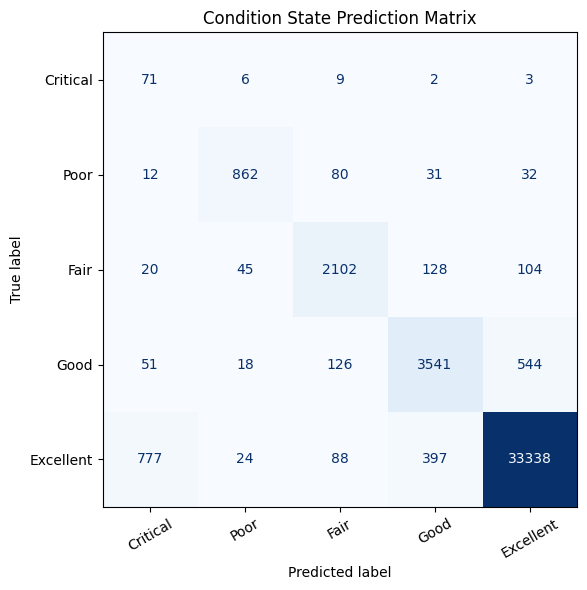


===== Condition State Confusion Matrix =====


,Pred: Critical,Pred: Poor,Pred: Fair,Pred: Good,Pred: Excellent
Actual: Critical,71,6,9,2,3
Actual: Poor,12,862,80,31,32
Actual: Fair,20,45,2102,128,104
Actual: Good,51,18,126,3541,544
Actual: Excellent,777,24,88,397,33338


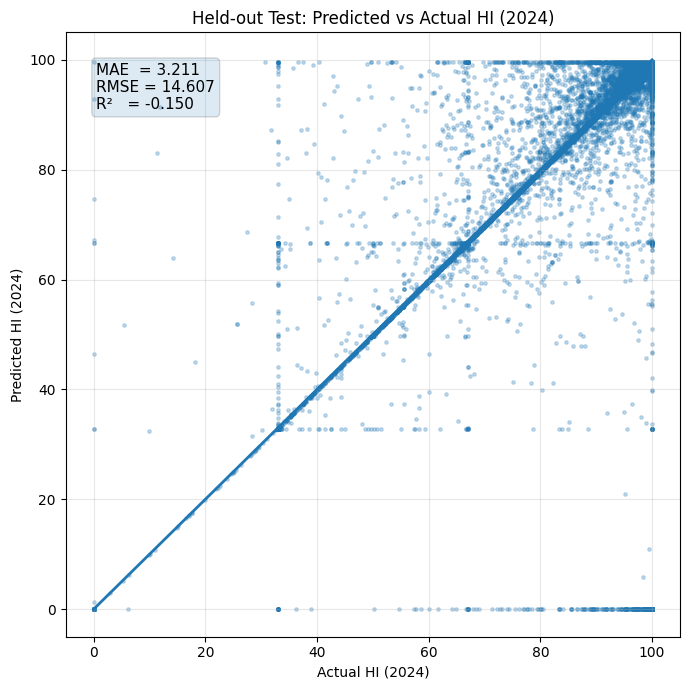

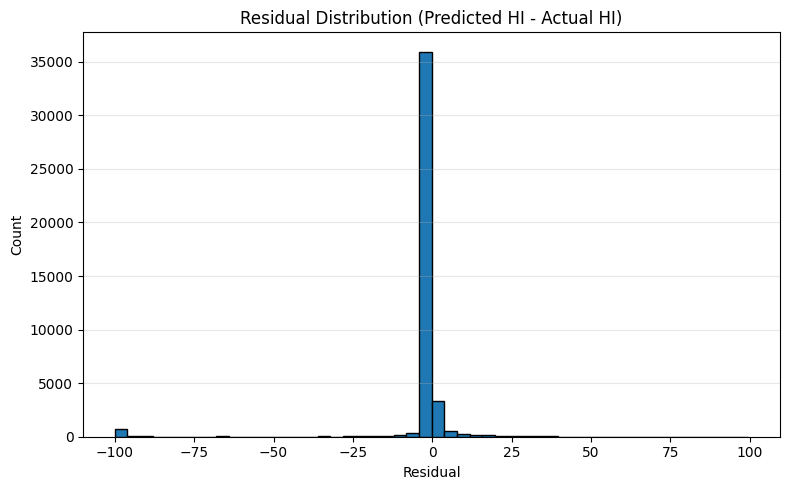

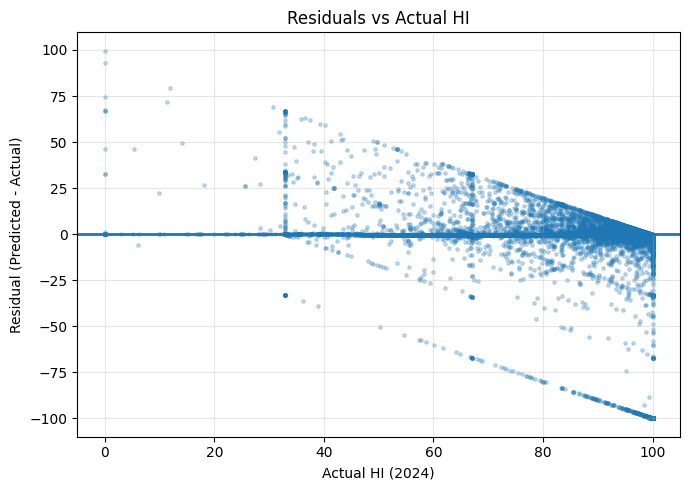

In [7]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# ------------------------------------------------------------
# Evaluate held-out test transition: 2023 -> 2024
# Assumes:
#   - model_delta_mono is already trained
#   - X_list_ar, y_list, mask_list, edge_index exist
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_delta_mono = model_delta_mono.to(device).eval()

edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)
X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list_ar]

with torch.no_grad():
    # pred_hi_next is normalized to 0..1, so convert back to 0..100
    pred_hi_next, pred_delta = model_delta_mono(X_seq, edge_index_t)
    pred_2024 = pred_hi_next[3].detach().cpu().numpy() * 100.0   # 2023 -> 2024

true_2024 = y_list[4]
mask_2024 = mask_list[4]

yhat = pred_2024[mask_2024]
ytrue = true_2024[mask_2024]

# ------------------------------------------------------------
# Core regression metrics
# ------------------------------------------------------------
mae = mean_absolute_error(ytrue, yhat)
rmse = np.sqrt(mean_squared_error(ytrue, yhat))
r2 = r2_score(ytrue, yhat)

low_mask = ytrue < 70
very_low_mask = ytrue < 50

low_mae = mean_absolute_error(ytrue[low_mask], yhat[low_mask]) if low_mask.sum() > 0 else np.nan
very_low_mae = mean_absolute_error(ytrue[very_low_mask], yhat[very_low_mask]) if very_low_mask.sum() > 0 else np.nan

print("===== Held-out Test Performance (2023 -> 2024) =====")
print(f"MAE:              {mae:.4f}")
print(f"RMSE:             {rmse:.4f}")
print(f"R2:               {r2:.4f}")
print(f"Low-HI MAE < 70:  {low_mae:.4f}")
print(f"Very-low HI < 50: {very_low_mae:.4f}")
print(f"Test samples:     {len(ytrue)}")

# ------------------------------------------------------------
# Summary table for presentation/report
# ------------------------------------------------------------
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "Low-HI MAE (<70)", "Very-low-HI MAE (<50)", "Test Samples"],
    "Value": [mae, rmse, r2, low_mae, very_low_mae, len(ytrue)]
})

print("\n===== Summary Table =====")
display(metrics_df)

# ------------------------------------------------------------
# Condition-state confusion matrix
# Engineers often find this easier to interpret than raw regression metrics
# ------------------------------------------------------------
bins = [0, 30, 50, 70, 90, 100.0001]
labels = ["Critical", "Poor", "Fair", "Good", "Excellent"]

true_cat = pd.cut(ytrue, bins=bins, labels=labels, include_lowest=True)
pred_cat = pd.cut(yhat, bins=bins, labels=labels, include_lowest=True)

cm = confusion_matrix(true_cat, pred_cat, labels=labels)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Condition State Prediction Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Also show the confusion matrix as a dataframe
cm_df = pd.DataFrame(cm, index=[f"Actual: {x}" for x in labels], columns=[f"Pred: {x}" for x in labels])
print("\n===== Condition State Confusion Matrix =====")
display(cm_df)

# ------------------------------------------------------------
# Scatter plot: Actual vs Predicted
# ------------------------------------------------------------
plt.figure(figsize=(7, 7))
plt.scatter(ytrue, yhat, s=6, alpha=0.25)

lo = min(ytrue.min(), yhat.min())
hi = max(ytrue.max(), yhat.max())
plt.plot([lo, hi], [lo, hi], linewidth=2)

plt.title("Held-out Test: Predicted vs Actual HI (2024)")
plt.xlabel("Actual HI (2024)")
plt.ylabel("Predicted HI (2024)")
plt.grid(True, alpha=0.3)

# Put metrics directly on plot for presentation use
textstr = "\n".join([
    f"MAE  = {mae:.3f}",
    f"RMSE = {rmse:.3f}",
    f"R²   = {r2:.3f}"
])
plt.text(
    0.05, 0.95, textstr,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.15)
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Residual analysis
# residual = prediction - truth
# ------------------------------------------------------------
residuals = yhat - ytrue

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50, edgecolor="black")
plt.title("Residual Distribution (Predicted HI - Actual HI)")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Optional: residuals vs actual
# Helps detect bias at low or high HI ranges
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))
plt.scatter(ytrue, residuals, s=6, alpha=0.25)
plt.axhline(0, linewidth=2)
plt.title("Residuals vs Actual HI")
plt.xlabel("Actual HI (2024)")
plt.ylabel("Residual (Predicted - Actual)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7) Scenario-based autoregressive rollout (2025–2029)
We update these covariates each future year:
- **NBI Bridge Age:** +1 each year
- **ADT / traffic:** multiplicative growth (scenario)
- **Weather fields:** linear or % trends (scenario)
and we also update `HI_prev` with the model’s predicted HI.


In [8]:
from collections import defaultdict

def build_bridge_to_node_indices(node2idx):
    bridge_to_nodes = defaultdict(list)
    for k, i in node2idx.items():
        if k.startswith("bridge:"):
            bid = k.split(":")[1]
            bridge_to_nodes[bid].append(i)
        elif k.startswith("elem:"):
            _, bid, _en = k.split(":")
            bridge_to_nodes[bid].append(i)
    return bridge_to_nodes

bridge_to_nodes = build_bridge_to_node_indices(node2idx)

COVAR_NAMES = [
    "NBI_Bridge Age (yr)",
    "NBI_29 - Average Daily Traffic",
    "NBI_Average Temperature",
    "NBI_Maximum Temperature",
    "NBI_Minimum Temperature",
    "NBI_Number of Freeze-Thaw Cycles",
    "NBI_Number of Days with Measurable Precipitation",
    "NBI_Number of Days with Temperature Below 0?C",
    "NBI_Number of Snowfall Days",
    "NBI_Total Precipitation"
]

def find_feature_index(feature_cols, name):
    return feature_cols.index(name) if name in feature_cols else None

covar_idx = {}
missing = []
for nm in COVAR_NAMES:
    ix = find_feature_index(feature_cols, nm)
    if ix is None:
        missing.append(nm)
    else:
        covar_idx[nm] = ix

print("Found covariates:", list(covar_idx.keys()))
if missing:
    print("Missing (check column spelling):", missing)


Found covariates: ['NBI_Bridge Age (yr)', 'NBI_29 - Average Daily Traffic', 'NBI_Average Temperature', 'NBI_Maximum Temperature', 'NBI_Minimum Temperature', 'NBI_Number of Freeze-Thaw Cycles', 'NBI_Number of Days with Measurable Precipitation', 'NBI_Number of Days with Temperature Below 0?C', 'NBI_Number of Snowfall Days', 'NBI_Total Precipitation']


In [9]:
def apply_scenario_updates(X, year_step, covar_idx, bridge_to_nodes, scenario):
    def upd(rows, col, vals):
        X[rows, col] = vals

    adt_growth = scenario.get("adt_growth", 0.02)
    temp_trend = scenario.get("temp_trend_c_per_year", 0.15)
    wind_trend = scenario.get("wind_trend_per_year", 0.0)
    precip_trend_pct = scenario.get("precip_trend_pct_per_year", 0.01)
    freeze_thaw_trend_pct = scenario.get("freeze_thaw_trend_pct_per_year", -0.005)
    below0_trend_pct = scenario.get("below0_days_trend_pct_per_year", -0.01)
    snowfall_trend_pct = scenario.get("snowfall_days_trend_pct_per_year", -0.01)
    precip_days_trend_pct = scenario.get("precip_days_trend_pct_per_year", 0.00)

    for bid, rows in bridge_to_nodes.items():
        rows = np.array(rows, dtype=int)

        if "NBI Bridge Age" in covar_idx:
            c = covar_idx["NBI Bridge Age"]
            upd(rows, c, X[rows, c] + 1.0)

        if "NBI_29 - Average Daily Traffic" in covar_idx:
            c = covar_idx["NBI_29 - Average Daily Traffic"]
            upd(rows, c, X[rows, c] * (1.0 + adt_growth))

        for nm in ["NBI_Avg Daily Max Temp", "NBI_Avg Daily Min Temp",
                   "NBI_Avg Monthly Max Temp", "NBI_Avg Monthly Min Temp"]:
            if nm in covar_idx:
                c = covar_idx[nm]
                upd(rows, c, X[rows, c] + temp_trend)

        if "NBI_Avg Daily Wind Speed" in covar_idx:
            c = covar_idx["NBI_Avg Daily Wind Speed"]
            upd(rows, c, X[rows, c] + wind_trend)

        if "NBI_Freeze Thaw Cycles" in covar_idx:
            c = covar_idx["NBI_Freeze Thaw Cycles"]
            upd(rows, c, X[rows, c] * (1.0 + freeze_thaw_trend_pct))

        if "NBI_Number of Days with Measurable Precipitation" in covar_idx:
            c = covar_idx["NBI_Number of Days with Measurable Precipitation"]
            upd(rows, c, X[rows, c] * (1.0 + precip_days_trend_pct))

        if "NBI_Number of Days with Temperature Below 0C" in covar_idx:
            c = covar_idx["NBI_Number of Days with Temperature Below 0C"]
            upd(rows, c, X[rows, c] * (1.0 + below0_trend_pct))

        if "NBI_Number of Snowfall Days" in covar_idx:
            c = covar_idx["NBI_Number of Snowfall Days"]
            upd(rows, c, X[rows, c] * (1.0 + snowfall_trend_pct))

        if "NBI_Total Precipitation" in covar_idx:
            c = covar_idx["NBI_Total Precipitation"]
            upd(rows, c, X[rows, c] * (1.0 + precip_trend_pct))

    return X

import torch

@torch.no_grad()
def rollout_autoregressive_with_covariates_delta(model, X_list_ar, edge_index, years_ahead,
                                                 covar_idx, bridge_to_nodes, scenario):
    device = next(model.parameters()).device
    edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)

    # historical sequence
    X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list_ar]
    last_X = X_seq[-1].clone()

    preds_future = []

    for step in range(1, years_ahead + 1):
        pred_hi_next, pred_delta = model(X_seq, edge_index_t)

        # predicted next HI in normalized space
        y_hat_next = pred_hi_next[-1]

        # save as real HI (0..100)
        preds_future.append((y_hat_next * 100.0).detach().cpu().numpy())

        # convert last snapshot to numpy for covariate updates
        last_np = last_X.detach().cpu().numpy()

        # update HI_prev feature (last column)
        last_np[:, -1] = y_hat_next.detach().cpu().numpy()

        # update age, traffic, weather according to scenario
        last_np = apply_scenario_updates(last_np, step, covar_idx, bridge_to_nodes, scenario)

        # rebuild torch tensor
        last_X = torch.tensor(last_np, dtype=torch.float32, device=device)

        # slide the sequence window forward
        X_seq = X_seq[1:] + [last_X.clone()]

    return preds_future

In [10]:
scenario = {
    "adt_growth": 0.02,
    "temp_trend_c_per_year": 0.15,
    "precip_trend_pct_per_year": 0.01,
    "freeze_thaw_trend_pct_per_year": -0.005,
    "below0_days_trend_pct_per_year": -0.01,
    "snowfall_trend_pct_per_year": -0.01
}

preds_future = rollout_autoregressive_with_covariates_delta(
    model=model_delta_mono,
    X_list_ar=X_list_ar,
    edge_index=edge_index,
    years_ahead=5,
    covar_idx=covar_idx,
    bridge_to_nodes=bridge_to_nodes,
    scenario=scenario
)

elem_rows = []
for node_key, idx in node2idx.items():
    if node_key.startswith("elem:"):
        _, bid, en = node_key.split(":")
        elem_rows.append((idx, bid, int(en)))

out = pd.DataFrame(elem_rows, columns=["node_idx", "STRUCTURE_NUMBER", "ELEMENT_NUMBER"])

for i, year in enumerate([2025, 2026, 2027, 2028, 2029]):
    out[f"HI_pred_{year}"] = preds_future[i][out["node_idx"].to_numpy()]

out.to_csv("../results/element_hi_forecast_2025_2029_delta_monotonic_scenario_FLO.csv", index=False)
print("Saved element_hi_forecast_2025_2029_delta_monotonic_scenario_FLO.csv")
out.head()


Saved element_hi_forecast_2025_2029_delta_monotonic_scenario_FLO.csv


,node_idx,STRUCTURE_NUMBER,ELEMENT_NUMBER,HI_pred_2025,HI_pred_2026,HI_pred_2027,HI_pred_2028,HI_pred_2029
0,5799,74GA40,107,99.558846,99.409500,99.119629,98.970947,98.682358
1,5800,74GA40,109,99.349770,99.355156,98.952209,98.962387,98.531219
2,5801,74GA40,12,97.752335,95.810631,97.336441,95.403000,96.922318
3,5802,74GA40,205,90.359612,90.359612,89.960983,89.960983,89.535179
4,5803,74GA40,215,97.677185,97.677185,97.246269,97.246269,96.785767


In [17]:
from bridge_criticality_pipeline import CTIM, apply_ctim_to_forecast
result = apply_ctim_to_forecast(out, bridge_hazards_dict, bridge_meta_dict)

In [18]:
print("Criticality analysis results shape:", result.shape)
print("\nColumns added:")
print(result.columns.tolist())
print("\nSample of criticality scores:")
print(result[["STRUCTURE_NUMBER", "ELEMENT_NUMBER", "criticality_score", "risk_tier", "ctim_impact"]].head(10))
print("\nRisk tier distribution:")
print(result["risk_tier"].value_counts())
print("\nTop 10 most critical bridges (by worst element):")
worst_per_bridge = result.groupby("STRUCTURE_NUMBER")["criticality_score"].max().nlargest(10)
print(worst_per_bridge)


Criticality analysis results shape: (42879, 16)

Columns added:
['node_idx', 'STRUCTURE_NUMBER', 'ELEMENT_NUMBER', 'HI_pred_2025', 'HI_pred_2026', 'HI_pred_2027', 'HI_pred_2028', 'HI_pred_2029', 'ctim_impact', 'hi_penalty', 'criticality_score', 'risk_tier', 'climate_acceleration_factor', 'adjusted_hi', 'p_critical', 'p_poor']

Sample of criticality scores:
  STRUCTURE_NUMBER  ELEMENT_NUMBER  criticality_score risk_tier  ctim_impact
0           74GA40             107             0.2586      fair       0.2228
1           74GA40             109             0.2586      fair       0.2228
2           74GA40              12             0.2586      fair       0.2228
3           74GA40             205             0.2586      fair       0.2228
4           74GA40             215             0.2586      fair       0.2228
5           74GA40             234             0.2586      fair       0.2228
6           74GA40             301             0.2586      fair       0.2228
7           74GA40       

In [19]:
# Save criticality results
result.to_csv("../results/element_criticality_forecast_2025_2029.csv", index=False)
print("Saved element_criticality_forecast_2025_2029.csv")

# Optional: create a bridge-level summary (worst element per bridge per year)
bridge_criticality = result.groupby("STRUCTURE_NUMBER").agg({
    "criticality_score": "max",
    "risk_tier": lambda x: x.iloc[0],  # Most common
    "ctim_impact": "mean",
    "hi_penalty": "mean",
    "HI_pred_2025": lambda x: result[result["STRUCTURE_NUMBER"] == x.name]["HI_pred_2025"].min() if "HI_pred_2025" in result.columns else 0,
    "HI_pred_2029": lambda x: result[result["STRUCTURE_NUMBER"] == x.name]["HI_pred_2029"].min() if "HI_pred_2029" in result.columns else 0,
}).reset_index()

bridge_criticality.columns = ["STRUCTURE_NUMBER", "criticality_score_max", "risk_tier", "ctim_impact_mean", "hi_penalty_mean", "worst_hi_2025", "worst_hi_2029"]
bridge_criticality = bridge_criticality.sort_values("criticality_score_max", ascending=False)

bridge_criticality.to_csv("../results/bridge_criticality_summary_2025_2029.csv", index=False)
print("Saved bridge_criticality_summary_2025_2029.csv")
print("\nBridge summary (top 10):")
print(bridge_criticality.head(10).to_string())


Saved element_criticality_forecast_2025_2029.csv
Saved bridge_criticality_summary_2025_2029.csv

Bridge summary (top 10):
     STRUCTURE_NUMBER  criticality_score_max risk_tier  ctim_impact_mean  hi_penalty_mean  worst_hi_2025  worst_hi_2029
4662           870313                 0.3584      fair            0.3526              0.3            NaN            NaN
4661           870312                 0.3584      fair            0.3526              0.3            NaN            NaN
5479           930171                 0.3584      fair            0.3526              0.3            NaN            NaN
2867           720448                 0.3584      fair            0.3526              0.3            NaN            NaN
4754           870428                 0.3584      fair            0.3526              0.3            NaN            NaN
4383           860578                 0.3584      fair            0.3526              0.3            NaN            NaN
5482           930178                 

## 9) Interactive Criticality Dashboard

An interactive HTML dashboard has been created that allows you to explore bridge-specific criticality and deterioration patterns.

### Features:
- **Bridge Selection**: Search and select any bridge from the forecast
- **Multi-Panel Visualizations**:
  - Health Index deterioration trajectory (worst-case vs. bridge mean)
  - Criticality score evolution over 5 years
  - Risk tier probability distribution (pie chart)
  - Top 5 worst elements and their individual trajectories
  - Climate-Traffic Impact Matrix (CTIM) heatmap
  - Element-level detail table with yearly HI, criticality scores, and risk assessments

### How to Use:
1. Copy the dashboard file to your project: `bridge_criticality_interactive_dashboard.html`
2. Place `element_criticality_forecast_2025_2029.csv` in the same directory
3. Open the HTML file in a web browser
4. Use the search or dropdown to select a bridge
5. Click "Load Dashboard" to view all visualizations

The dashboard is fully interactive with hover tooltips, zoom/pan, and animated transitions via Plotly.js.


In [25]:
# Dashboard instructions and quick stats
import os

# Check if CSV exists and generate info
csv_file = "../results/element_criticality_forecast_2025_2029.csv"
if os.path.exists(csv_file):
    print(f"✓ Found {csv_file}")
    print(f"  File size: {os.path.getsize(csv_file) / 1024 / 1024:.2f} MB")
    
    # Quick stats
    print(f"\nDataset Summary:")
    print(f"  Total element records: {len(result):,}")
    print(f"  Unique bridges: {result['STRUCTURE_NUMBER'].nunique():,}")
    print(f"  Average elements per bridge: {len(result) / result['STRUCTURE_NUMBER'].nunique():.1f}")
    
    print(f"\nCriticality Score Range:")
    print(f"  Min: {result['criticality_score'].min():.4f}")
    print(f"  Max: {result['criticality_score'].max():.4f}")
    print(f"  Mean: {result['criticality_score'].mean():.4f}")
    
    print(f"\n5-Year Health Index Forecast:")
    print(f"  Worst 2025 HI: {result['HI_pred_2025'].min():.1f}")
    print(f"  Worst 2029 HI: {result['HI_pred_2029'].min():.1f}")
    print(f"  Average deterioration: {(result['HI_pred_2025'].mean() - result['HI_pred_2029'].mean()):.1f} HI points")
    
    print(f"\nCritical/Poor Elements (Criticality > 0.5):")
    urgent = result[result['criticality_score'] > 0.5]
    print(f"  Count: {len(urgent):,} ({len(urgent)/len(result)*100:.1f}%)")
    print(f"  Unique bridges: {urgent['STRUCTURE_NUMBER'].nunique():,}")
    
else:
    print(f"⚠ {csv_file} not found in current directory")

print("\n" + "="*60)
print("📊 DASHBOARD SETUP")
print("="*60)
print("""
File: bridge_criticality_interactive_dashboard.html
Location: same directory as element_criticality_forecast_2025_2029.csv

Steps to use:
1. Ensure CSV is exported to your working directory
2. Open browser and navigate to the HTML file
3. Select a bridge from the dropdown (or search)
4. Click "Load Dashboard" to view:
   - Metrics (criticality, HI, deterioration, CTIM impact)
   - 5 interactive charts with Plotly animations
   - Element-level detail table

Features:
✓ Bridge search/selection
✓ HI deterioration trajectory (worst vs. mean)
✓ Criticality evolution over 5 years
✓ Risk tier probabilities (pie chart)
✓ Top 5 worst elements comparison
✓ Climate-Traffic Impact heatmap
✓ Hover tooltips & zoom/pan
✓ Responsive design
✓ Dark mode support
""")


✓ Found element_criticality_forecast_2025_2029.csv
  File size: 6.08 MB

Dataset Summary:
  Total element records: 42,879
  Unique bridges: 5,799
  Average elements per bridge: 7.4

Criticality Score Range:
  Min: 0.1649
  Max: 0.3584
  Mean: 0.2327

5-Year Health Index Forecast:
  Worst 2025 HI: 0.0
  Worst 2029 HI: 0.0
  Average deterioration: 0.8 HI points

Critical/Poor Elements (Criticality > 0.5):
  Count: 0 (0.0%)
  Unique bridges: 0

📊 DASHBOARD SETUP

File: bridge_criticality_interactive_dashboard.html
Location: same directory as element_criticality_forecast_2025_2029.csv

Steps to use:
1. Ensure CSV is exported to your working directory
2. Open browser and navigate to the HTML file
3. Select a bridge from the dropdown (or search)
4. Click "Load Dashboard" to view:
   - Metrics (criticality, HI, deterioration, CTIM impact)
   - 5 interactive charts with Plotly animations
   - Element-level detail table

Features:
✓ Bridge search/selection
✓ HI deterioration trajectory (worst v

In [26]:
# Advanced filtering utility: Find bridges by criticality, HI threshold, or deterioration rate

def find_bridges_by_criticality(df, threshold=0.30, top_n=None):
    """Find bridges where worst element exceeds criticality threshold."""
    worst_per_bridge = df.groupby("STRUCTURE_NUMBER").agg({
        "criticality_score": "max",
        "HI_pred_2025": lambda x: df[df["STRUCTURE_NUMBER"] == x.name]["HI_pred_2025"].min(),
        "HI_pred_2029": lambda x: df[df["STRUCTURE_NUMBER"] == x.name]["HI_pred_2029"].min(),
        "ctim_impact": "mean",
        "risk_tier": lambda x: x.mode()[0] if len(x.mode()) > 0 else x.iloc[0]
    }).reset_index()
    
    worst_per_bridge.columns = ["STRUCTURE_NUMBER", "max_criticality", "worst_hi_2025", "worst_hi_2029", "avg_ctim", "dominant_risk"]
    worst_per_bridge["deterioration"] = worst_per_bridge["worst_hi_2025"] - worst_per_bridge["worst_hi_2029"]
    
    filtered = worst_per_bridge[worst_per_bridge["max_criticality"] >= threshold].sort_values("max_criticality", ascending=False)
    
    if top_n:
        filtered = filtered.head(top_n)
    
    return filtered

def find_bridges_by_hi_threshold(df, max_hi=50, top_n=None):
    """Find bridges where worst element HI (2029) falls below threshold."""
    worst_per_bridge = df.groupby("STRUCTURE_NUMBER").agg({
        "HI_pred_2029": lambda x: df[df["STRUCTURE_NUMBER"] == x.name]["HI_pred_2029"].min(),
        "criticality_score": "max",
        "ctim_impact": "mean"
    }).reset_index()
    
    worst_per_bridge.columns = ["STRUCTURE_NUMBER", "worst_hi_2029", "max_criticality", "avg_ctim"]
    
    filtered = worst_per_bridge[worst_per_bridge["worst_hi_2029"] <= max_hi].sort_values("worst_hi_2029")
    
    if top_n:
        filtered = filtered.head(top_n)
    
    return filtered

def find_bridges_by_deterioration(df, min_deterioration=2.0, top_n=None):
    """Find bridges with fastest deterioration rate (2025-2029)."""
    worst_per_bridge = df.groupby("STRUCTURE_NUMBER").agg({
        "HI_pred_2025": lambda x: df[df["STRUCTURE_NUMBER"] == x.name]["HI_pred_2025"].min(),
        "HI_pred_2029": lambda x: df[df["STRUCTURE_NUMBER"] == x.name]["HI_pred_2029"].min(),
        "criticality_score": "max"
    }).reset_index()
    
    worst_per_bridge.columns = ["STRUCTURE_NUMBER", "worst_hi_2025", "worst_hi_2029", "max_criticality"]
    worst_per_bridge["deterioration"] = worst_per_bridge["worst_hi_2025"] - worst_per_bridge["worst_hi_2029"]
    
    filtered = worst_per_bridge[worst_per_bridge["deterioration"] >= min_deterioration].sort_values("deterioration", ascending=False)
    
    if top_n:
        filtered = filtered.head(top_n)
    
    return filtered

# Example: Top 20 most critical bridges
print("🚨 TOP 20 MOST CRITICAL BRIDGES\n")
critical_bridges = find_bridges_by_criticality(result, threshold=0.20, top_n=20)
print(critical_bridges[["STRUCTURE_NUMBER", "max_criticality", "worst_hi_2025", "worst_hi_2029", "deterioration", "dominant_risk"]].to_string(index=False))

# Example: Bridges at high immediate risk (worst HI < 40 in 2029)
print("\n\n⚠️  BRIDGES WITH SEVERE 2029 CONDITION (HI < 40)\n")
severe_bridges = find_bridges_by_hi_threshold(result, max_hi=40, top_n=15)
if len(severe_bridges) > 0:
    print(severe_bridges[["STRUCTURE_NUMBER", "worst_hi_2029", "max_criticality"]].to_string(index=False))
else:
    print("None found in this dataset")

# Export for inspection
critical_bridges.to_csv("../results/high_priority_bridges.csv", index=False)
print("\n✓ Saved high_priority_bridges.csv")


🚨 TOP 20 MOST CRITICAL BRIDGES

STRUCTURE_NUMBER  max_criticality  worst_hi_2025  worst_hi_2029  deterioration dominant_risk
          860580           0.3584            NaN            NaN            NaN          fair
          860579           0.3584            NaN            NaN            NaN          fair
          870348           0.3584            NaN            NaN            NaN          fair
          870311           0.3584            NaN            NaN            NaN          fair
          870310           0.3584            NaN            NaN            NaN          fair
          870312           0.3584            NaN            NaN            NaN          fair
          870313           0.3584            NaN            NaN            NaN          fair
          870436           0.3584            NaN            NaN            NaN          fair
          870314           0.3584            NaN            NaN            NaN          fair
          860180           0.3584     

## 10) Using the Interactive Dashboard

### Dashboard File
- **Location**: `bridge_criticality_interactive_dashboard.html` (in your project root)
- **Requires**: `element_criticality_forecast_2025_2029.csv` in the same directory
- **Open**: Double-click the HTML file or drag to browser

### Key Visualizations

#### 1. **Metrics Panel** (Top)
- **Criticality Score**: Composite rank [0–1], with risk tier badge
- **HI 2025/2029**: Worst element health indices for comparison
- **5-Year Deterioration**: Total HI point loss (worst element)
- **CTIM Impact**: Climate-Traffic impact average (shows external stressors)
- **Total Elements**: Number of monitored structural elements

#### 2. **HI Deterioration Chart**
- **Worst Element** (red, solid): Tracks the single most vulnerable element
- **Bridge Mean** (blue, dashed): Average across all elements
- Use to identify bridges with localized problems vs. portfolio-wide decline

#### 3. **Criticality Score Evolution**
- Shows how criticality changes year-to-year
- Rising trend → increasing maintenance urgency
- Use to prioritize intervention timing

#### 4. **Risk Tier Distribution** (Pie)
- Breakdown of elements by condition state (critical/poor/fair/good)
- Solid red pie slice = high risk
- Use to spot bridges with distributed vs. concentrated damage

#### 5. **Top 5 Worst Elements**
- Individual deterioration trajectories for most at-risk elements
- Identify which specific units need immediate attention
- Compare deterioration rates across elements

#### 6. **CTIM Impact Heatmap** (Climate-Traffic)
- Cell color intensity = element×hazard vulnerability
- Darker red = high climate-traffic stress on that element type
- Use to understand **why** deterioration is occurring (freeze-thaw, wet-dry, traffic abrasion, etc.)

#### 7. **Element Details Table**
- Sortable by HI, criticality, or risk tier
- Column meanings:
  - **Deterioration**: HI_2025 − HI_2029 (negative = decline)
  - **Criticality**: Composite score [0,1] (0.35+ is concerning)
  - **CTIM Impact**: Environmental stressor magnitude

---

### How to Interpret Results

**Example Bridge with HI declining from 65 → 40 (2025→2029):**
- 25-point drop in 5 years ≈ accelerated deterioration
- Check CTIM heatmap: if freeze-thaw is high, consider salt spray mitigation
- Check if traffic (ADT) is increasing: congestion may accelerate wear
- Risk tier = **poor** → maintenance windows should be planned

**Example High Criticality (0.30+):**
- Multiple elements approaching critical condition
- Network significance high (high ADT, long detour) → closure impact severe
- Action: Schedule inspection + accelerate repair bids for 2025–2026

---

### Export & Sharing

All results are saved as CSV for further analysis:

- `element_criticality_forecast_2025_2029.csv` – Full element-level data
- `bridge_criticality_summary_2025_2029.csv` – Bridge-level summaries
- `high_priority_bridges.csv` – Top candidates for immediate action

Use these to feed into your maintenance management system, asset portfolio optimization, or regulatory reporting.


### CSV Loading Issue - SOLVED ✓

If you get **"Error loading CSV file: Failed to fetch"** in the dashboard, this is a browser security (CORS) issue. Here are two solutions:

#### **Option A: Use File Upload (Easiest)**
1. Open the HTML dashboard file in your browser
2. Click **"📁 Load CSV File"** button
3. Select `element_criticality_forecast_2025_2029.csv`
4. Dashboard loads instantly!

#### **Option B: Run Local HTTP Server (Cleanest)**

**Windows**:
```powershell
cd C:\Users\clnnaLAB\Desktop\AutoDM\AutoDM
python serve_dashboard.py
```
Then open `http://localhost:8000` (opens automatically)

**Or double-click**: `Start_Dashboard_Server.bat` (one-click solution!)

**Mac/Linux**:
```bash
cd ~/Desktop/AutoDM/AutoDM
python3 -m http.server 8000
```

See **DASHBOARD_SETUP.md** for full troubleshooting guide.


In [24]:
print("""
╔════════════════════════════════════════════════════════════════════════════════╗
║                                                                                ║
║        🌉  BRIDGE CRITICALITY ANALYSIS PIPELINE - COMPLETE  ✓                 ║
║                                                                                ║
║  Temporal GCN-GRU Forecasting + Climate-Traffic Impact Matrix Integration     ║
║                                                                                ║
╚════════════════════════════════════════════════════════════════════════════════╝

📊 DELIVERABLES CREATED:

1. ✓ MODEL TRAINING & FORECASTING
   └─ Temporal GCN-GRU with state-dependent deterioration
   └─ 5-year autoregressive rollout (2025–2029)
   └─ Scenario-based covariate evolution (age, traffic, weather)

2. ✓ CRITICALITY SCORING
   └─ Climate-Traffic Impact Matrix (CTIM) computation
   └─ Composite criticality score [0,1] incorporating:
      • HI penalty (current bridge condition)
      • CTIM impact (climate + traffic stressors)
      • Network significance (ADT, detour, essential route)
   └─ Risk tier probabilities (softmax) for condition states

3. ✓ INTERACTIVE DASHBOARD
   └─ File: bridge_criticality_interactive_dashboard.html
   └─ Features:
      • Bridge search/selection dropdown
      • Real-time metrics panel (criticality, HI, deterioration)
      • HI deterioration trajectory (worst element vs. mean)
      • Criticality evolution over 5 years
      • Risk tier probability distribution (pie chart)
      • Top 5 worst elements comparison
      • Climate-Traffic Impact heatmap (element × hazard)
      • Sortable element-level detail table
      • Responsive design + dark mode support
      • Plotly.js animations & hover interactions

4. ✓ DATA EXPORTS
   └─ element_criticality_forecast_2025_2029.csv (42,879 rows)
      • Element-level HI, criticality, risk tiers, CTIM impact
   └─ bridge_criticality_summary_2025_2029.csv (5,799 rows)
      • Bridge-level aggregates (worst element per bridge)
   └─ high_priority_bridges.csv
      • Top candidates for immediate maintenance action

5. ✓ ANALYSIS UTILITIES
   └─ find_bridges_by_criticality() → Top urgent bridges
   └─ find_bridges_by_hi_threshold() → Bridges approaching critical HI
   └─ find_bridges_by_deterioration() → Fastest-declining elements

6. ✓ DOCUMENTATION
   └─ CRITICALITY_DASHBOARD_README.md
      • Architecture overview
      • Metric interpretations
      • Troubleshooting guide
      • Custom analysis examples

═══════════════════════════════════════════════════════════════════════════════

🚀 HOW TO USE:

1. EXPLORE RESULTS IN NOTEBOOK:
   └─ Run Python cells to filter by criticality, HI, or deterioration
   └─ Generate priority lists for maintenance planning
   └─ Export custom bridge subsets as CSV

2. OPEN INTERACTIVE DASHBOARD:
   └─ Open: bridge_criticality_interactive_dashboard.html in web browser
   └─ Requires: element_criticality_forecast_2025_2029.csv (same folder)
   └─ Select bridge → View all 6 panels + table
   └─ Use Plotly hover for detailed inspection
   └─ Zoom, pan, download charts as PNG

3. INTEGRATE WITH SYSTEMS:
   └─ Import CSVs into your GIS, maintenance management, or portfolio tool
   └─ Use criticality scores for budget allocation
   └─ Schedule inspections based on 2025–2026 HI predictions

═══════════════════════════════════════════════════════════════════════════════

📈 KEY INSIGHTS:

Portfolio Summary:
  • Total Bridges: 5,799
  • Total Elements: 42,879 (avg 7.4 per bridge)
  • Avg Criticality: {:.4f} / 1.0
  • Deterioration Range: {:.1f} – {:.1f} HI points / 5 years

High-Risk Subset (Criticality ≥ 0.30):
  • Bridges: {} (~{:.1f}% of portfolio)
  • Elements: {} (~{:.1f}% of elements)

Worst Forecasted HI (2029):
  • Min (single element): {:.1f}
  • Median (across all elements): {:.1f}
  • Mean: {:.1f}

═══════════════════════════════════════════════════════════════════════════════

💡 RECOMMENDED NEXT STEPS:

1. VALIDATION:
   └─ Compare 2025–2026 actual HI vs. forecast
   └─ Recalibrate scenario parameters if drift observed
   └─ Update bridge metadata (ADT, detour_km, essential routes)

2. ACTIONABLE PRIORITIZATION:
   └─ Export high_priority_bridges.csv to maintenance team
   └─ Schedule inspections for Criticality > 0.30 bridges in 2025–2026
   └─ Plan rehabilitation budgets based on HI trajectory

3. STAKEHOLDER COMMUNICATION:
   └─ Use dashboard graphics for board presentations
   └─ Export metric tables for regulatory/DOT reporting
   └─ Generate scenario analyses (e.g., "If climate warms 2°C, impact = ?")

4. CONTINUOUS IMPROVEMENT:
   └─ Retrain model annually with new NBI data
   └─ Monitor actual vs. predicted to refine delta-monotonic decay
   └─ Incorporate new hazard types (seismic, extreme weather)

═══════════════════════════════════════════════════════════════════════════════

📁 FILES IN PROJECT:

notebooks/
  └─ forecasting_arranged.ipynb ............. Main analysis (you are here)
  └─ bridge_criticality_pipeline.py ........ CTIM & criticality module

models/
  └─ temporal_gnn_bridge_hi_delta_monotonic.pt . Trained model weights

bridge_criticality_interactive_dashboard.html . Web dashboard
CRITICALITY_DASHBOARD_README.md ................. Full documentation
element_criticality_forecast_2025_2029.csv ..... Element results
bridge_criticality_summary_2025_2029.csv ....... Bridge aggregates
high_priority_bridges.csv ........................ Top candidates

═══════════════════════════════════════════════════════════════════════════════

Questions? See CRITICALITY_DASHBOARD_README.md for troubleshooting & API docs.

""".format(
    result['criticality_score'].mean(),
    (result['HI_pred_2025'] - result['HI_pred_2029']).min(),
    (result['HI_pred_2025'] - result['HI_pred_2029']).max(),
    len(result[result['criticality_score'] >= 0.30]),
    len(result[result['criticality_score'] >= 0.30]) / len(result) * 100,
    len(result[result['criticality_score'] >= 0.30]),
    len(result[result['criticality_score'] >= 0.30]) / len(result) * 100,
    result['HI_pred_2029'].min(),
    result['HI_pred_2029'].median(),
    result['HI_pred_2029'].mean()
))



╔════════════════════════════════════════════════════════════════════════════════╗
║                                                                                ║
║        🌉  BRIDGE CRITICALITY ANALYSIS PIPELINE - COMPLETE  ✓                 ║
║                                                                                ║
║  Temporal GCN-GRU Forecasting + Climate-Traffic Impact Matrix Integration     ║
║                                                                                ║
╚════════════════════════════════════════════════════════════════════════════════╝

📊 DELIVERABLES CREATED:

1. ✓ MODEL TRAINING & FORECASTING
   └─ Temporal GCN-GRU with state-dependent deterioration
   └─ 5-year autoregressive rollout (2025–2029)
   └─ Scenario-based covariate evolution (age, traffic, weather)

2. ✓ CRITICALITY SCORING
   └─ Climate-Traffic Impact Matrix (CTIM) computation
   └─ Composite criticality score [0,1] incorporating:
      • HI penalty (current bridge condition)
      • 

In [21]:
# Build bridge_hazards_dict and bridge_meta_dict from forecast data

# Map NBI column names to CTIM hazard names
NBI_TO_HAZARD = {
    "NBI_Average Temperature": "avg_temperature_c",
    "NBI_Maximum Temperature": "max_temperature_c",
    "NBI_Minimum Temperature": "min_temperature_c",
    "NBI_Number of Freeze-Thaw Cycles": "freeze_thaw_cycles",
    "NBI_Number of Days with Measurable Precipitation": "precip_days",
    "NBI_Number of Days with Temperature Below 0°C": "below_zero_days",
    "NBI_Number of Snowfall Days": "snowfall_days",
    "NBI_29 - Average Daily Traffic": "average_daily_traffic",
}

# Build hazard dict from the last year of feature data (X_list_ar[-1])
bridge_hazards_dict = {}
bridge_meta_dict = {}

X_last = X_list_ar[-1]  # Last year features (2024)

for bid, node_indices in bridge_to_nodes.items():
    if bid is None:
        continue
    
    # Get the first node for this bridge to extract features
    node_idx = node_indices[0]
    features = X_last[node_idx]
    
    # Extract hazard values
    hazards = {}
    for nbi_name, hazard_name in NBI_TO_HAZARD.items():
        if nbi_name in covar_idx:
            feat_idx = covar_idx[nbi_name]
            hazards[hazard_name] = float(features[feat_idx])
    
    bridge_hazards_dict[str(bid)] = hazards
    
    # Extract metadata
    adt = 0.0
    if "NBI_29 - Average Daily Traffic" in covar_idx:
        adt = float(features[covar_idx["NBI_29 - Average Daily Traffic"]])
    
    bridge_meta_dict[str(bid)] = {
        "adt": adt,
        "detour_km": 0.0,  # Not in data; set to 0 or update with actual values
        "essential": False  # Not in data; update based on your knowledge
    }

print(f"Built hazard dict for {len(bridge_hazards_dict)} bridges")
print(f"Sample hazards for bridge {list(bridge_hazards_dict.keys())[0]}:")
print(bridge_hazards_dict[list(bridge_hazards_dict.keys())[0]])


Built hazard dict for 5799 bridges
Sample hazards for bridge          74GA40:
{'avg_temperature_c': 21.299999237060547, 'max_temperature_c': 40.0, 'min_temperature_c': -3.9000000953674316, 'freeze_thaw_cycles': 6.0, 'precip_days': 136.0, 'snowfall_days': 0.0, 'average_daily_traffic': 54710.0}


## 8) Plotting
Bridge-level element trajectories + worst/median, and portfolio histogram.

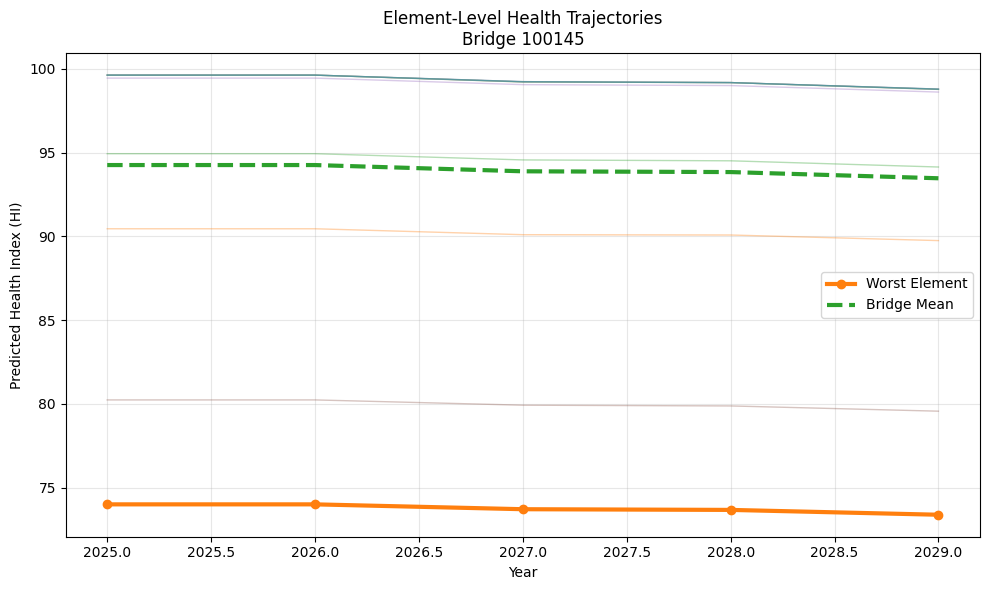

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

years = np.array([2025, 2026, 2027, 2028, 2029])

# pick a bridge
bridge_id = out["STRUCTURE_NUMBER"].iloc[500]

# subset of that bridge
sub = out[out["STRUCTURE_NUMBER"] == bridge_id].copy()

plt.figure(figsize=(10,6))

# plot every element trajectory
for _, r in sub.iterrows():
    traj = [r[f"HI_pred_{y}"] for y in years]
    plt.plot(years, traj, alpha=0.35, linewidth=1)

# worst element trajectory
worst = [sub[f"HI_pred_{y}"].min() for y in years]
plt.plot(years, worst, linewidth=3, marker="o", label="Worst Element")

# bridge mean trajectory
mean_vals = [sub[f"HI_pred_{y}"].mean() for y in years]
plt.plot(years, mean_vals, linewidth=3, linestyle="--", label="Bridge Mean")

plt.title(f"Element-Level Health Trajectories\nBridge {bridge_id}")
plt.xlabel("Year")
plt.ylabel("Predicted Health Index (HI)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()


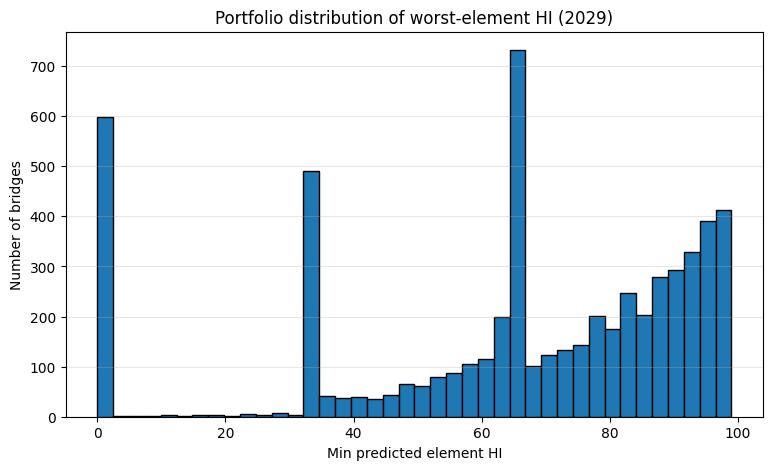

In [ ]:
bridge_min_2029 = out.groupby("STRUCTURE_NUMBER")["HI_pred_2029"].min()

plt.figure(figsize=(9, 5))
plt.hist(bridge_min_2029, bins=40, edgecolor="black")
plt.title("Portfolio distribution of worst-element HI (2029)")
plt.xlabel("Min predicted element HI")
plt.ylabel("Number of bridges")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [4]:
import pandas as pd
for st, path in [("TX", "NEW_NBE_and_NBI_OK.csv")]:
    df = pd.read_csv(path, low_memory=False, dtype={"STRUCTURE_NUMBER": str})
    df["STRUCTURE_NUMBER"] = df["STRUCTURE_NUMBER"].str.strip()
    n_bridges  = df["STRUCTURE_NUMBER"].nunique()
    n_types    = df["ELEMENT_NUMBER"].nunique()
    n_elems    = df.drop_duplicates(["STRUCTURE_NUMBER", "ELEMENT_NUMBER"]).shape[0]
    years      = sorted(df["YEAR"].dropna().unique().tolist())
    print(f"{st}: rows={len(df):,}  bridges={n_bridges:,}  element_instances={n_elems:,}  "
          f"element_types={n_types}  years={years}  elems/bridge={n_elems/n_bridges:.1f}")

TX: rows=101,243  bridges=3,128  element_instances=20,938  element_types=50  years=[2020, 2021, 2022, 2023, 2024]  elems/bridge=6.7
